In [14]:
import numpy as np
import pandas as pd
import joblib
import json
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, confusion_matrix

In [2]:
X_test = pd.read_csv("X_test.csv")
y_test = pd.read_csv("y_test.csv").squeeze()

model = joblib.load("xgb_tuned.joblib")

In [3]:
y_proba = model.predict_proba(X_test)[:, 1]

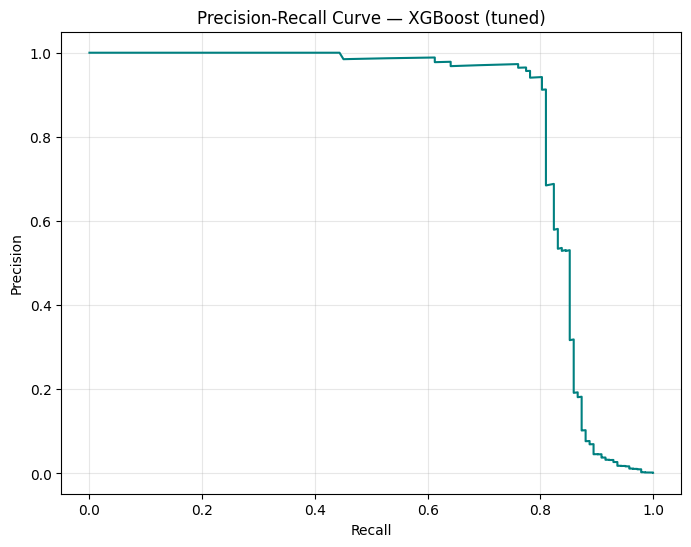

In [4]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color="teal")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — XGBoost (tuned)")
plt.grid(alpha=0.3)
plt.show()

In [5]:
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_f1_idx = np.argmax(f1_scores)
best_f1_threshold = thresholds[best_f1_idx]

print(f"Best F1 threshold: {best_f1_threshold:.4f}")
print(f"At this threshold -> Precision: {precisions[best_f1_idx]:.4f}, Recall: {recalls[best_f1_idx]:.4f}, F1: {f1_scores[best_f1_idx]:.4f}")

Best F1 threshold: 0.2352
At this threshold -> Precision: 0.9421, Recall: 0.8028, F1: 0.8669


In [6]:
# Average fraud Amount dataset se nikalo (real number)
fraud_amounts = pd.read_csv("creditcard.csv")
avg_fraud_amount = fraud_amounts[fraud_amounts["Class"] == 1]["Amount"].mean()
print(f"Average fraud amount: ${avg_fraud_amount:.2f}")

COST_FALSE_NEGATIVE = avg_fraud_amount   # ek miss hone wale fraud ki asal keemat
COST_FALSE_POSITIVE = 5.0                # ek false alarm handle karne ka andaza (assumption)

Average fraud amount: $122.21


In [7]:
costs = []

In [8]:
for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    total_cost = (fn * COST_FALSE_NEGATIVE) + (fp * COST_FALSE_POSITIVE)
    costs.append(total_cost)

In [9]:
costs = np.array(costs)
best_cost_idx = np.argmin(costs)
best_cost_threshold = thresholds[best_cost_idx]

print(f"Best cost-optimal threshold: {best_cost_threshold:.4f}")
print(f"Minimum total cost: ${costs[best_cost_idx]:,.2f}")
print(f"Cost at default 0.5 threshold: ${costs[np.argmin(np.abs(thresholds - 0.5))]:,.2f}")

Best cost-optimal threshold: 0.0048
Minimum total cost: $3,101.44
Cost at default 0.5 threshold: $3,813.55


In [10]:
y_pred_best_cost = (y_proba >= best_cost_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_best_cost).ravel()

print(f"True Positives (fraud caught): {tp}")
print(f"False Negatives (fraud missed): {fn}")
print(f"False Positives (genuine wrongly flagged): {fp}")
print(f"True Negatives: {tn}")
print(f"Total flagged as fraud: {tp + fp}")
print(f"Percentage of all test transactions flagged: {(tp+fp)/len(y_test)*100:.2f}%")

True Positives (fraud caught): 121
False Negatives (fraud missed): 21
False Positives (genuine wrongly flagged): 107
True Negatives: 84869
Total flagged as fraud: 228
Percentage of all test transactions flagged: 0.27%


In [11]:
y_pred_best_f1 = (y_proba >= best_f1_threshold).astype(int)
tn_f1, fp_f1, fn_f1, tp_f1 = confusion_matrix(y_test, y_pred_best_f1).ravel()

print(f"F1-optimal threshold ({best_f1_threshold:.4f}):")
print(f"TP: {tp_f1}, FN: {fn_f1}, FP: {fp_f1}, TN: {tn_f1}")

F1-optimal threshold (0.2352):
TP: 114, FN: 28, FP: 7, TN: 84969


In [12]:
FINAL_THRESHOLD = best_cost_threshold

In [13]:
joblib.dump(model, "final_model.joblib")

['final_model.joblib']

In [15]:
with open("final_threshold.json", "w") as f:
    json.dump({"threshold": float(FINAL_THRESHOLD)}, f)

print(f"Final model and threshold ({FINAL_THRESHOLD:.4f}) saved")

Final model and threshold (0.0048) saved
